# 02 — Evaluate Climatology-Matched (`clim`) and Observationally Matched (`obs`) ICs Against Actual 2015

This notebook evaluates how closely the selected candidate years from the `clim` and `obs` branches match the **actual 2015 BruteForce restarts** across the four sensitivity-test initialization dates (`2015-02-01`, `2015-05-01`, `2015-08-01`, `2015-11-01`).

All evaluation functions are implemented in [`util/ic_eval.py`](util/ic_eval.py), and all tables and figures are saved to `/global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/`.

### Contents
1. **Configuration & selection summary** (`clim` vs `obs` selected years)
2. **Distance & rank evaluation against actual 2015** (`evaluate_distance_ranks`, `plot_distance_vs_truth`)
3. **Field-level similarity metrics (`d_box`, `r_box`, `d_grid`, `r_grid`, `RMSE`, `bias`)** (`field_similarity_table`, `plot_field_similarity_bars`)
4. **Global & hemispheric integrated restart summary** (`global_summary_table`)
5. **Large-scale ($30^\circ \times 60^\circ$ box) standardized anomaly maps** (`plot_box_spatial`)

In [1]:
from pathlib import Path
import sys
import IPython.display as ipd
import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path("util").resolve()))
import ic_eval as ice

ice.ensure_proj_data()
plt.rcParams["figure.dpi"] = 120

SRC_ROOT   = Path("/global/cfs/cdirs/e3sm/zhan391/v3.LR.S2D.ENSINT/BruteForce")
# Observation setup for land (elm) and sea ice (mpassi); None uses default ERA5 setup
OBS_ROOT   = {"elm": None, "mpassi": None}
OBS_FIELDS = {"elm": None, "mpassi": None}
OUT_ROOT   = Path("/global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions")
CACHE_DIR  = OUT_ROOT / "cache"
DIAG_ROOT  = Path("/global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic")
SAVE_DIAG  = True

TEST_DATES   = ["2015-02-01", "2015-05-01", "2015-08-01", "2015-11-01"]
EXAMPLE_DATE = "2015-02-01"
BOX          = (30.0, 60.0)

plans, distances, selections = ice.load_test_selections(
    TEST_DATES, SRC_ROOT, OUT_ROOT, obs_root=OBS_ROOT, obs_fields=OBS_FIELDS, box=BOX, cache_dir=CACHE_DIR
)
for td in TEST_DATES:
    print(f"{td}: clim={selections['clim', td]['mpassi']}  obs={selections['obs', td]['mpassi']}")

2015-02-01: clim=1995  obs=1990
2015-05-01: clim=1995  obs=2014
2015-08-01: clim=1988  obs=2017
2015-11-01: clim=2000  obs=1995


## 1. Distance and Rank Against Actual 2015

Each candidate year $y \in [1980, 2018] \setminus \{2015\}$ is scored directly against the actual 2015 BruteForce restart on $30^\circ \times 60^\circ$ boxes (`D_true`, Rank 1 = closest to actual 2015 among the 38 candidate years).

[TABLE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/data/2015_branch_rank_summary.csv


,target_date,closest to 2015 (obs fields),min D_true (obs fields),closest to 2015 (all fields),min D_true (all fields),clim year,clim: D_true (obs fields),clim: rank (obs fields),clim: rank corr (obs),clim: D_true (all fields),clim: rank (all fields),obs year,obs: D_true (obs fields),obs: rank (obs fields),obs: rank corr (obs),obs: D_true (all fields),obs: rank (all fields)
0,2015-02-01,2018,1.119,2014,1.171,1995,1.347,12,0.190,1.515,16,1990,1.128,3,0.636,1.400,6
1,2015-05-01,2014,0.873,2014,0.967,1995,1.194,4,0.378,1.359,7,2014,0.873,1,0.936,0.967,1
2,2015-08-01,2002,0.939,2009,0.995,1988,1.479,23,0.321,1.462,24,2017,0.980,3,0.972,1.319,13
3,2015-11-01,2017,1.097,2018,1.065,2000,1.525,27,-0.024,1.464,23,1995,1.294,7,0.725,1.221,8


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/figure/2015_distance_vs_truth_scatter.png


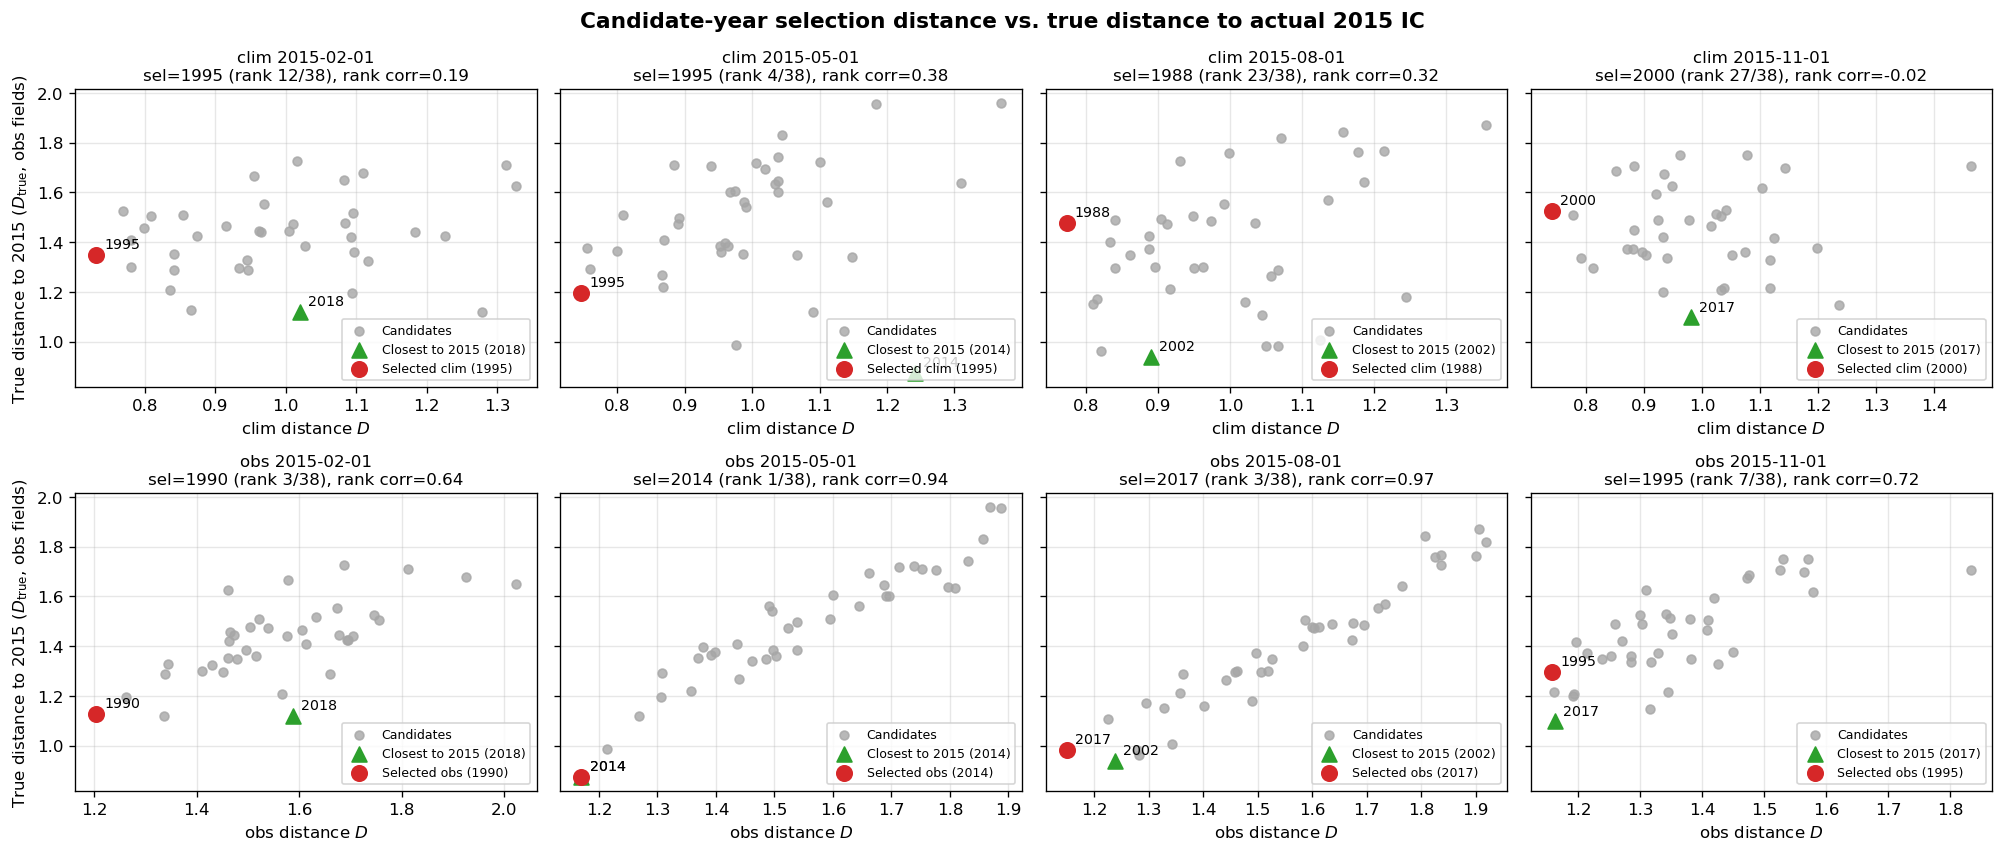

In [2]:
rank_summary_df, truth_obs, truth_all = ice.evaluate_distance_ranks(
    TEST_DATES, plans, distances, box=BOX, cache_dir=CACHE_DIR
)
ice.save_table(rank_summary_df, "2015_branch_rank_summary", DIAG_ROOT, SAVE_DIAG)
ipd.display(rank_summary_df.round(3))

fig = ice.plot_distance_vs_truth(TEST_DATES, distances, truth_obs)
ice.save_fig(fig, "2015_distance_vs_truth_scatter", DIAG_ROOT, SAVE_DIAG)
plt.show()

## 2. Field-Level Similarity Metrics (`d_box`, `r_box`, `d_grid`, `r_grid`, `RMSE`, `bias`)

For every key sea-ice and land field, we compare `clim`, `obs`, and `ERA5` against the actual 2015 state on both $30^\circ \times 60^\circ$ boxes and the native model grid.

[TABLE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/data/2015_field_similarity_all_dates.csv


,target_date,component,field,units,source,year,d_box,r_box,d_grid,r_grid,RMSE,bias
0,2015-02-01,elm,snow water equivalent,mm,clim,1995,1.163,0.067,1.671,-0.353,45.277,0.076
1,2015-02-01,elm,snow water equivalent,mm,obs,1990,1.429,-0.454,1.696,-0.399,45.947,1.570
2,2015-02-01,elm,snow water equivalent,mm,ERA5,2015,1.094,0.308,1.589,0.037,NaN,NaN
3,2015-02-01,elm,surface soil water,kg m$^{-2}$,clim,1995,1.444,-0.207,1.554,-0.181,6.379,-0.281
4,2015-02-01,elm,surface soil water,kg m$^{-2}$,obs,1990,1.052,0.434,1.508,-0.041,6.188,0.263
5,2015-02-01,elm,surface soil water,kg m$^{-2}$,ERA5,2015,1.220,0.420,1.297,0.234,NaN,NaN
6,2015-02-01,elm,subsurface soil water,kg m$^{-2}$,clim,1995,1.401,-0.070,1.505,-0.158,55.424,2.069
7,2015-02-01,elm,subsurface soil water,kg m$^{-2}$,obs,1990,1.282,0.184,1.423,-0.055,52.421,4.093
8,2015-02-01,elm,subsurface soil water,kg m$^{-2}$,ERA5,2015,1.892,0.240,1.714,0.166,NaN,NaN
9,2015-02-01,elm,surface soil temperature,K,clim,1995,1.175,0.073,1.173,0.110,2.842,-0.440


[TABLE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/data/2015_field_similarity_4season_mean.csv


d_box  r_box  d_grid  r_grid  \
component field                    source                                 
elm       snow water equivalent    ERA5    1.117  0.217   1.648   0.029   
                                   clim    1.179 -0.188   1.731  -0.355   
                                   obs     0.983  0.243   1.235   0.184   
          subsurface soil water    ERA5    1.763  0.140   1.744   0.169   
                                   clim    1.516 -0.141   1.584  -0.168   
                                   obs     1.288  0.117   1.385   0.134   
          surface soil temperature ERA5    0.601  0.732   0.842   0.601   
                                   clim    1.318 -0.032   1.269   0.111   
                                   obs     1.238  0.106   1.326   0.041   
          surface soil water       ERA5    1.066  0.479   1.271   0.323   
                                   clim    1.352 -0.048   1.550  -0.079   
                                   obs     1.258  0.080   1.441   0.048   
mpassi    NH ice concentration     ERA5    0.588  0.852   1.057   0.519   
                                   clim    1.280 -0.243   1.436  -0.046   
                                   obs     0.977  0.178   1.341   0.094   
          NH ice thickness         clim    1.019  0.041   1.251  -0.054   
                                   obs     0.768  0.595   1.067   0.286   
          NH snow on ice           clim    1.029  0.100   1.274  -0.015   
                                   obs     0.828  0.650   1.135   0.319   
          SH ice concentration     ERA5    0.639  0.847   1.047   0.511   
                                   clim    1.487 -0.471   1.381  -0.078   
                                   obs     0.806  0.695   1.170   0.288   
          SH ice thickness         clim    1.834 -0.771   1.475  -0.113   
                                   obs     1.302  0.246   1.438   0.095   
          SH snow on ice           clim    1.951 -0.269   1.724  -0.132   
                                   obs     1.893 -0.001   1.742  -0.041   

                                             RMSE   bias  
component field                    source                 
elm       snow water equivalent    ERA5       NaN    NaN  
                                   clim    41.762  0.763  
                                   obs     30.100  0.973  
          subsurface soil water    ERA5       NaN    NaN  
                                   clim    58.820  6.003  
                                   obs     51.410  3.784  
          surface soil temperature ERA5       NaN    NaN  
                                   clim     3.157 -0.588  
                                   obs      3.297 -0.375  
          surface soil water       ERA5       NaN    NaN  
                                   clim     6.077 -0.015  
                                   obs      5.648  0.020  
mpassi    NH ice concentration     ERA5       NaN    NaN  
                                   clim     0.080  0.005  
                                   obs      0.075  0.002  
          NH ice thickness         clim     0.243  0.028  
                                   obs      0.207  0.007  
          NH snow on ice           clim     0.027  0.001  
                                   obs      0.024  0.000  
          SH ice concentration     ERA5       NaN    NaN  
                                   clim     0.081 -0.003  
                                   obs      0.068 -0.003  
          SH ice thickness         clim     0.170 -0.010  
                                   obs      0.165 -0.007  
          SH snow on ice           clim     0.041 -0.003  
                                   obs      0.042 -0.003

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/figure/2015_field_similarity_bars.png


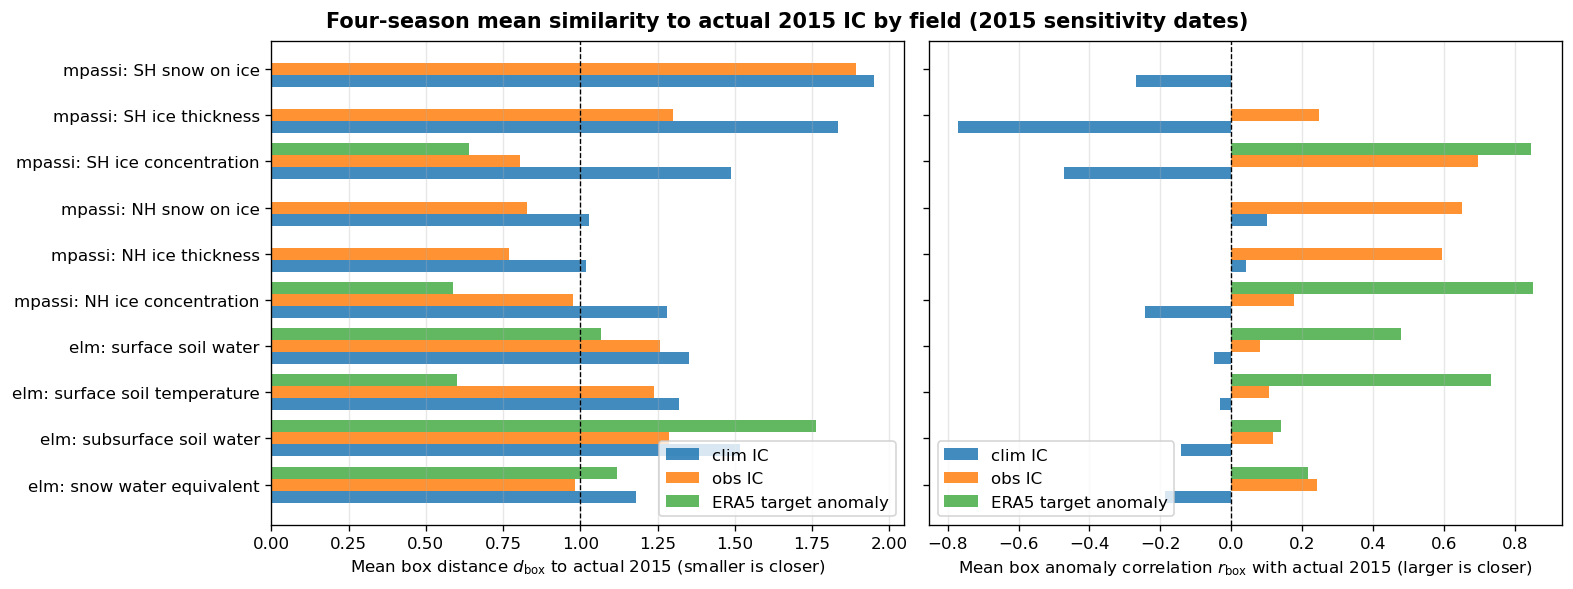

In [3]:
sim_all = pd.concat([
    ice.field_similarity_table(
        plans["clim", td], 2015,
        {"clim": selections["clim", td]["mpassi"], "obs": selections["obs", td]["mpassi"]},
        box=BOX, cache_dir=CACHE_DIR, log=lambda *_: None,
    )
    for td in TEST_DATES
], ignore_index=True)

ice.save_table(sim_all, "2015_field_similarity_all_dates", DIAG_ROOT, SAVE_DIAG)
ipd.display(sim_all[sim_all["target_date"] == EXAMPLE_DATE].round(3))

mean_by_source = (
    sim_all.groupby(["component", "field", "source"])[["d_box", "r_box", "d_grid", "r_grid", "RMSE", "bias"]]
    .mean()
    .round(3)
)
ice.save_table(mean_by_source.reset_index(), "2015_field_similarity_4season_mean", DIAG_ROOT, SAVE_DIAG)
ipd.display(mean_by_source)

fig = ice.plot_field_similarity_bars(sim_all)
ice.save_fig(fig, "2015_field_similarity_bars", DIAG_ROOT, SAVE_DIAG)
plt.show()

## 3. Global & Hemispheric Integrated Restart Summary (`Actual 2015` vs `clim` vs `obs`)

In [4]:
summary_2015_df = ice.global_summary_table(TEST_DATES, selections, SRC_ROOT)
ice.save_table(summary_2015_df, "2015_global_integrated_summary", DIAG_ROOT, SAVE_DIAG)
ipd.display(summary_2015_df.round(3))

[TABLE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/data/2015_global_integrated_summary.csv


,target_date,component,quantity,actual_2015,clim year,clim,clim - actual,obs year,obs,obs - actual
0,2015-02-01,elm,mean H2OSNO (mm),348.912,1995,351.249,2.337,1990,352.492,3.580
1,2015-02-01,elm,snow-covered column fraction,0.626,1995,0.635,0.009,1990,0.640,0.014
2,2015-02-01,elm,top-3-layer soil liquid (kg m-2),10.719,1995,10.464,-0.255,1990,10.655,-0.064
3,2015-02-01,elm,top-3-layer soil ice (kg m-2),35.257,1995,35.234,-0.023,1990,35.626,0.369
4,2015-02-01,elm,top soil layer T (K),270.704,1995,270.002,-0.702,1990,270.025,-0.679
...,...,...,...,...,...,...,...,...,...,...
63,2015-11-01,mpassi,NH snow volume (1e3 km3),0.591,2000,0.924,0.334,1995,0.439,-0.151
64,2015-11-01,mpassi,SH ice area (1e6 km2),15.250,2000,15.894,0.644,1995,15.009,-0.241
65,2015-11-01,mpassi,SH ice extent >15% (1e6 km2),18.094,2000,18.642,0.547,1995,17.487,-0.607
66,2015-11-01,mpassi,SH ice volume (1e3 km3),21.476,2000,20.740,-0.736,1995,20.348,-1.127


## 4. $30^\circ \times 60^\circ$ Box-Scale Standardized Anomaly Maps

Since candidate years are selected using $30^\circ \times 60^\circ$ box-averaged standardized anomalies, these maps show what the selection metric directly sees.

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/figure/box30x60_z_mpassi_nh_ice_concentration_20150201.png


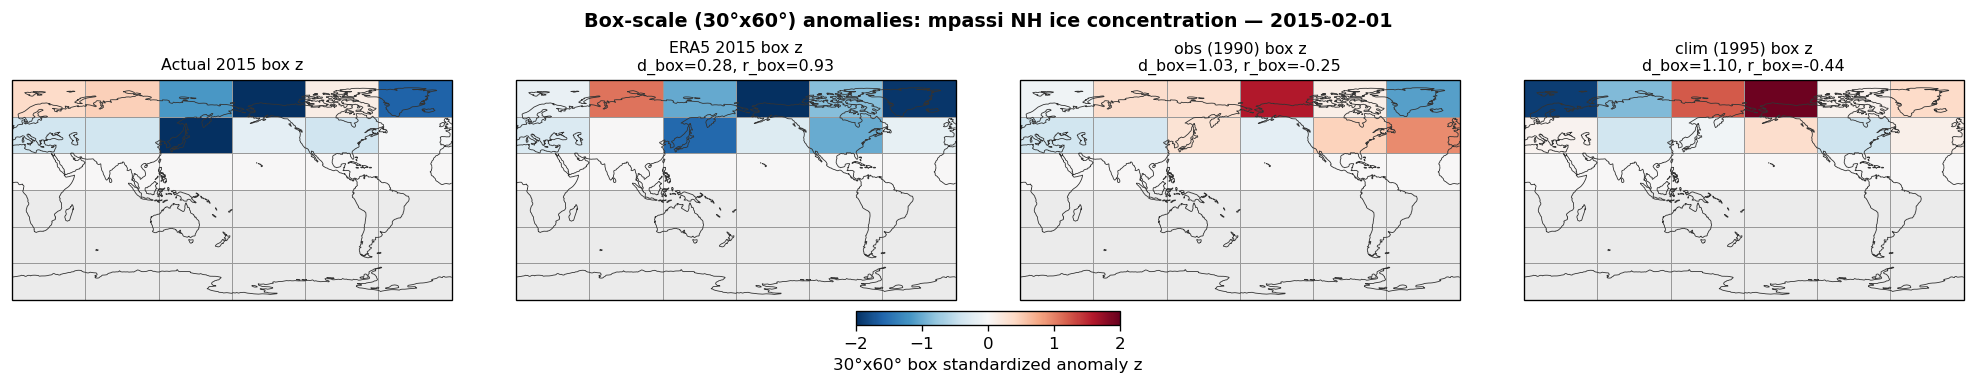

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/figure/box30x60_z_mpassi_sh_ice_concentration_20150201.png


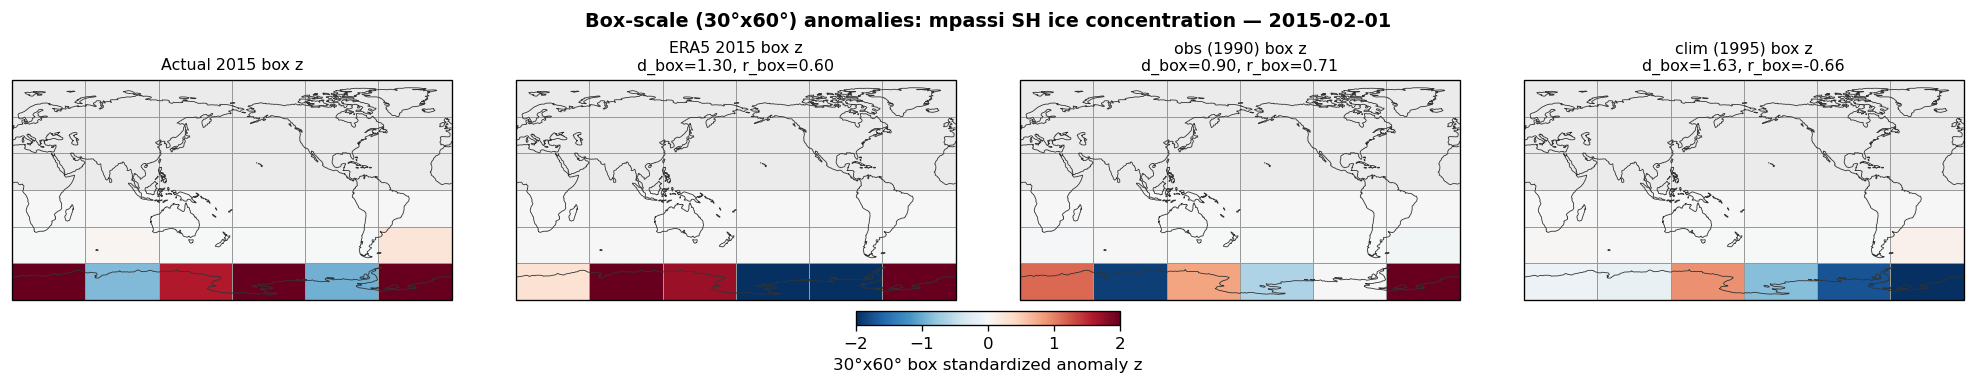

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/figure/box30x60_z_elm_snow_water_equivalent_20150201.png


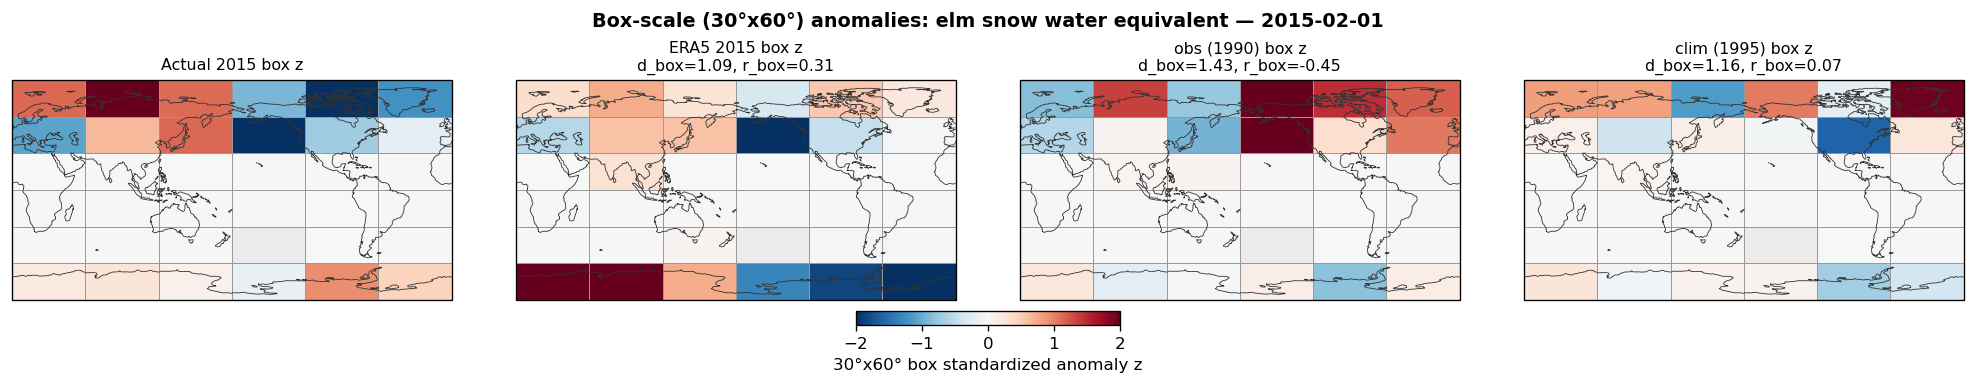

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/figure/box30x60_z_elm_surface_soil_water_20150201.png


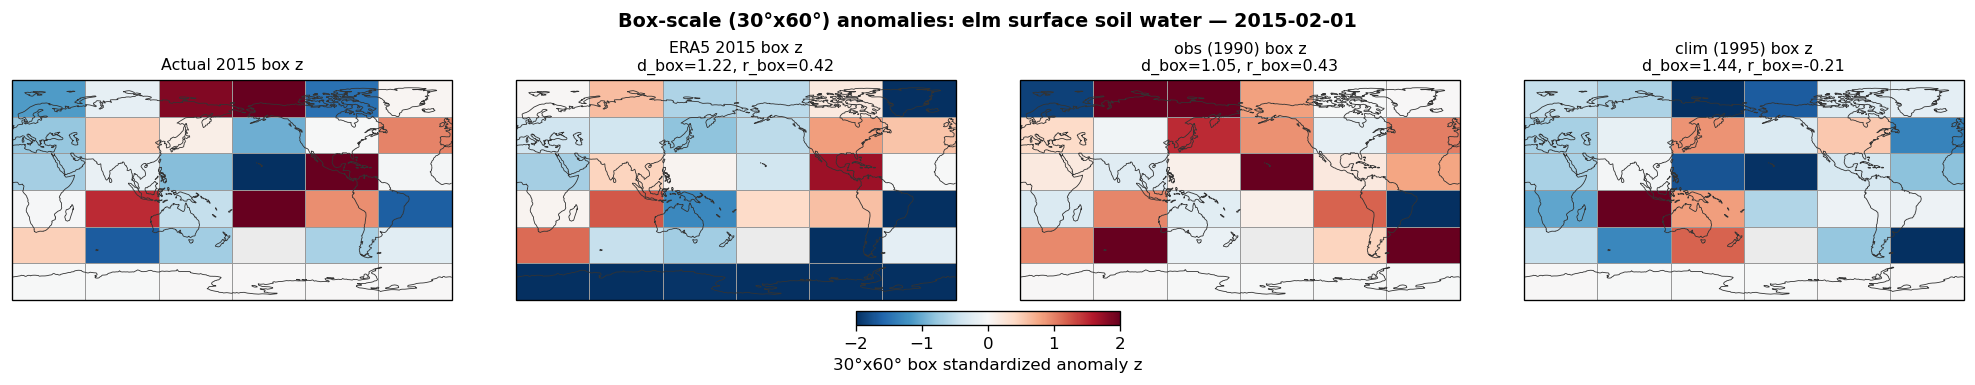

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/figure/box30x60_z_elm_subsurface_soil_water_20150201.png


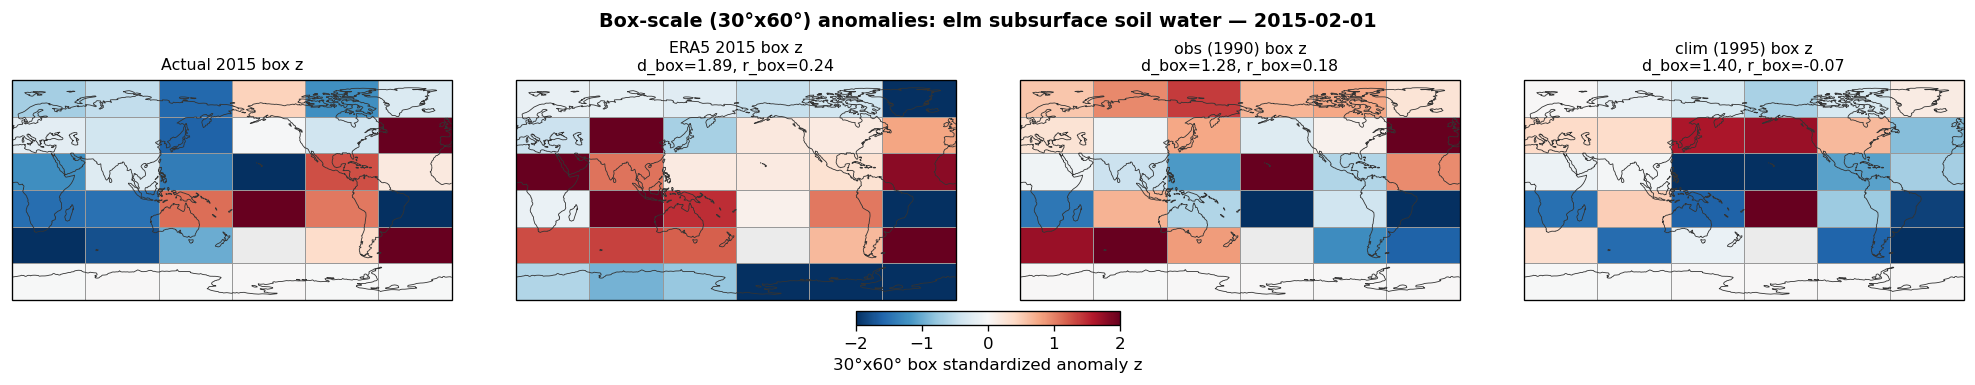

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/figure/box30x60_z_elm_surface_soil_temperature_20150201.png


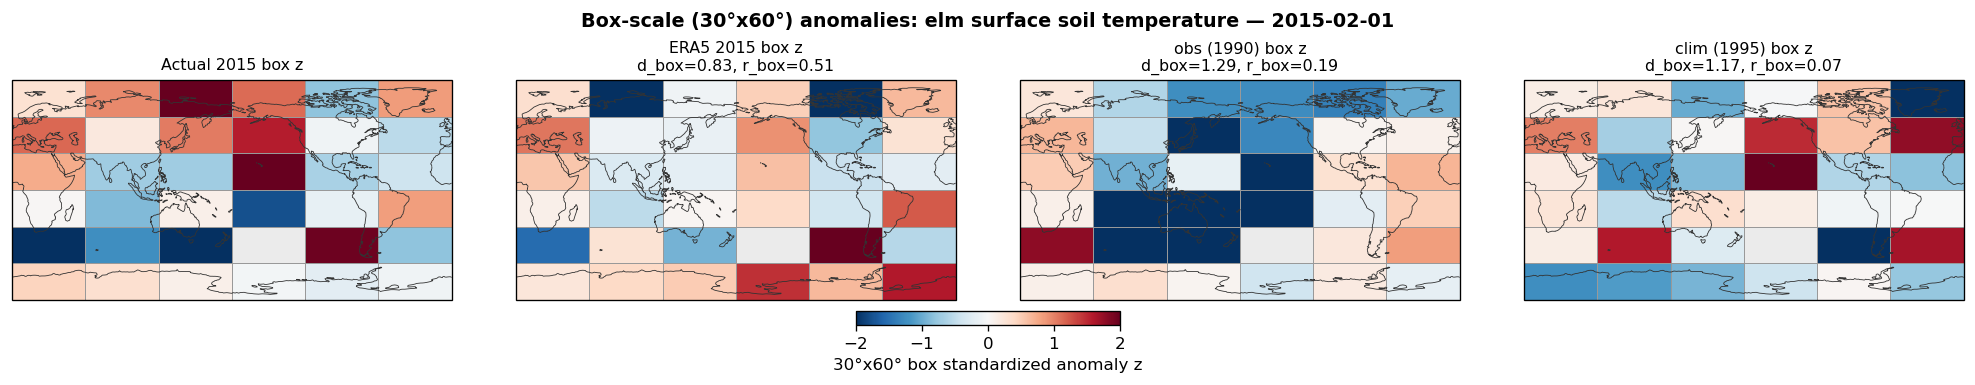

In [5]:
plan_ex = plans["clim", EXAMPLE_DATE]
byears_ex = {
    "clim": selections["clim", EXAMPLE_DATE]["mpassi"],
    "obs": selections["obs", EXAMPLE_DATE]["mpassi"],
}

box_fields = [
    ("mpassi", "NH ice concentration"),
    ("mpassi", "SH ice concentration"),
    ("elm", "snow water equivalent"),
    ("elm", "surface soil water"),
    ("elm", "subsurface soil water"),
    ("elm", "surface soil temperature"),
]

for comp, fname in box_fields:
    sp = ice.prepare_spatial_field(
        plan_ex, comp, fname, 2015, byears_ex, box=BOX, cache_dir=CACHE_DIR, log=lambda *_: None
    )
    fig = ice.plot_box_spatial(sp, z_lim=2.0)
    ice.save_fig(
        fig, f"box30x60_z_{comp}_{ice.slugify(fname)}_{EXAMPLE_DATE.replace('-', '')}",
        DIAG_ROOT, SAVE_DIAG,
    )
    plt.show()